# ENSAMBLE METHODS


## IMPORTS AND SETUP

In [3]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)

    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt

    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

Cloning into 'Weather_forecasting'...
remote: Enumerating objects: 284, done.
remote: Counting objects: 100% (284/284), done.
remote: Compressing objects: 100% (220/220), done.
remote: Total 284 (delta 131), reused 208 (delta 57), pack-reused 0 (from 0)
Receiving objects: 100% (284/284), 8.19 MiB | 23.76 MiB/s, done.
Resolving deltas: 100% (131/131), done.
 [OK] Ambiente rilevato: Google Colab
 [OK] Directory di lavoro impostata a: /content/Weather_forecasting


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import optuna
import src.utils.metrics as metrics

from itertools import product

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from sklearn.multioutput import MultiOutputRegressor

from src.data.preprocessing import get_split

RANDOM_STATE = 42

In [ ]:
# RUNNARE QUESTA CELLA, TOGLIENDO IL COMMENTO MULTI-LINEA, SOLO SE SI VUOLE RICARICARE RISULTATI SALVATI IN PRECEDENZA

'''import joblib
from google.colab import files

uploaded = files.upload()

artifact_path = next(iter(uploaded))

artifacts = joblib.load(artifact_path)

models = artifacts["models"]

rf = models["Random Forest"]
et = models["Extra Trees"]
gb = models["Gradient Boosting"]
xgb = models["XGBoost"]

X_train = artifacts["data"]["X_train"]
X_val = artifacts["data"]["X_val"]
X_test = artifacts["data"]["X_test"]

y_train = artifacts["data"]["y_train"]
y_val = artifacts["data"]["y_val"]
y_test = artifacts["data"]["y_test"]

study_results = artifacts["study_results"]

test_predictions = artifacts["test_predictions"]
comparison_tables = artifacts["comparison_tables"]
summary_scores = artifacts["summary_scores"]

target_scales = artifacts["target_scales"]

print("All artifacts restored successfully.")'''

## DATASET

In [ ]:
split = get_split()
features = split.get_features()

# Temperature targets
split.define_target("t2m_mean")
(X_train, yt_train), (X_val, yt_val), (X_test, yt_test) = split.get(features)

# Precipitation targets
split.define_target("tp_mm")
(_, yp_train), (_, yp_val), (_, yp_test) = split.get(features)

# Combine temperature and precipitation targets
y_train = pd.concat({"t2m_mean": yt_train, "tp_mm": yp_train}, axis=1)
y_val   = pd.concat({"t2m_mean": yt_val,   "tp_mm": yp_val},   axis=1)
y_test  = pd.concat({"t2m_mean": yt_test,  "tp_mm": yp_test},  axis=1)

target_scales = y_train.std(axis=0, ddof=0).replace(0, 1)

print("Dataset shapes:")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

Dataset shapes:
X_train: (10168, 26) | y_train: (10168, 60)
X_val:   (1431, 26) | y_val:   (1431, 60)
X_test:  (1430, 26) | y_test:  (1430, 60)


## RANDOM FOREST

### DEFAULT PERFORMANCE

In [ ]:
rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    rf.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    rf.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

print(f"Number of trees: {rf.n_estimators}")
print("Training completed.")

Number of trees: 100
Training completed.


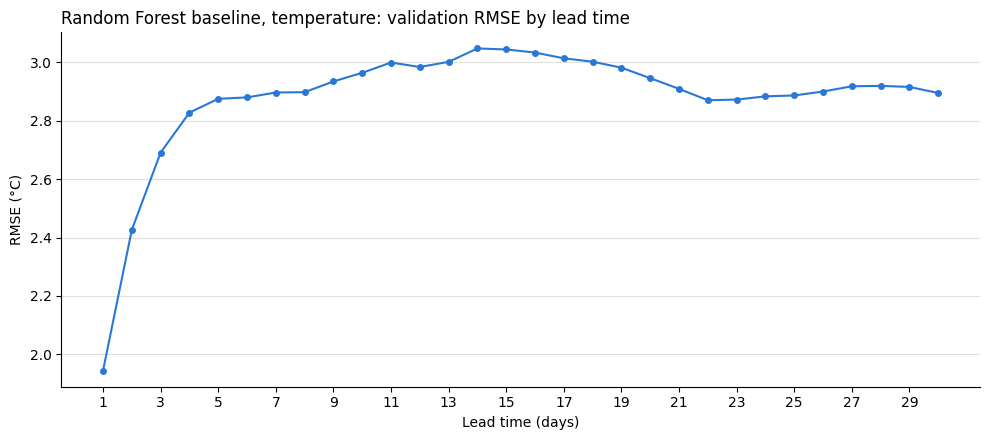

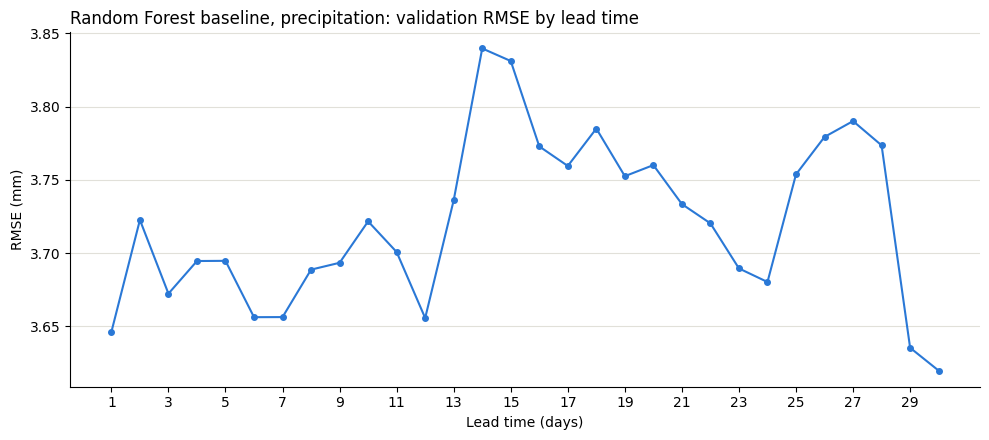

In [ ]:
# Temperature evaluation
metrics.plot_rmse(
    y_val["t2m_mean"],
    y_val_pred["t2m_mean"],
    "Random Forest baseline, temperature: validation RMSE by lead time",
    "°C"
)

table = metrics.metrics_table(
    {
        "Train": (y_train["t2m_mean"], y_train_pred["t2m_mean"]),
        "Val": (y_val["t2m_mean"], y_val_pred["t2m_mean"])
    },
    tolerance=2
)

display(table.style.format("{:.3f}"))


# Precipitation evaluation
metrics.plot_rmse(
    y_val["tp_mm"],
    y_val_pred["tp_mm"],
    "Random Forest baseline, precipitation: validation RMSE by lead time",
    "mm"
)

table = metrics.metrics_table(
    {
        "Train": (y_train["tp_mm"], y_train_pred["tp_mm"]),
        "Val": (y_val["tp_mm"], y_val_pred["tp_mm"])
    }
)

display(table.style.format("{:.3f}"))

### MANUAL HYPERPARAMETER SEARCH

In [ ]:
def evaluate_rf_config(max_depth, min_samples_leaf, max_features):

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = pd.DataFrame(
        model.predict(X_val),
        index=y_val.index,
        columns=y_val.columns
    )

    normalized_mae = (
        (y_val - y_pred).abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": max_features,
        "Val normalized MAE": normalized_mae,
        "Val temp MAE": metrics.get_mean_absolute_error(
            y_val["t2m_mean"], y_pred["t2m_mean"]
        ),
        "Val precip MAE": metrics.get_mean_absolute_error(
            y_val["tp_mm"], y_pred["tp_mm"]
        )
    }

In [ ]:
depths = [10, 20, None]
min_leaves = [1, 10, 30]
max_features_options = [0.5, 0.7, 1.0]

results = []

for depth, min_leaf, max_features in product(
    depths, min_leaves, max_features_options
):
    results.append(
        evaluate_rf_config(depth, min_leaf, max_features)
    )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("Val normalized MAE")
    .reset_index(drop=True)
    .round(4)
)

,max_depth,min_samples_leaf,max_features,Val normalized MAE,Val temp MAE,Val precip MAE
0,10.0,30,1.0,0.4137,2.1368,1.9944
1,10.0,30,0.5,0.4138,2.1186,2.0032
2,NaN,30,0.7,0.4139,2.1232,2.0020
3,20.0,30,0.7,0.4139,2.1232,2.0020
4,20.0,30,1.0,0.4140,2.1390,1.9949
5,NaN,30,1.0,0.4140,2.1390,1.9949
6,20.0,30,0.5,0.4140,2.1184,2.0048
7,NaN,30,0.5,0.4140,2.1184,2.0048
8,10.0,30,0.7,0.4140,2.1215,2.0037
9,10.0,10,0.5,0.4219,2.1312,2.0564


### OPTUNA

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators", 100, 400, step=100
    )

    max_depth = trial.suggest_categorical(
        "max_depth", [8, 10, 12, 15, 20, None]
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 10, 80, log=True
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2 * min_samples_leaf,
        500,
        log=True
    )

    max_features = trial.suggest_categorical(
        "max_features", [0.5, 0.7, 1.0]
    )

    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    normalized_mae = (
        np.abs(y_val.to_numpy() - y_pred)
        / target_scales.to_numpy()
    ).mean()

    return normalized_mae


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study_rf = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study_rf.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

print("Best validation normalized MAE:", study_rf.best_value)
print("Best hyperparameters:", study_rf.best_params)

[I 2026-11-25 10:23:42,582] A new study created in memory with name: no-name-9e438ead-47e7-4361-9fb2-6a4b90f6c2b7


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-25 10:24:33,612] Trial 0 finished with value: 0.4139245068533267 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 60, 'min_samples_split': 283, 'max_features': 1.0}. Best is trial 0 with value: 0.4139245068533267.
[I 2026-11-25 10:26:35,101] Trial 1 finished with value: 0.4131460776246135 and parameters: {'n_estimators': 400, 'max_depth': 20, 'min_samples_leaf': 18, 'min_samples_split': 179, 'max_features': 1.0}. Best is trial 1 with value: 0.4131460776246135.
[I 2026-11-25 10:27:24,417] Trial 2 finished with value: 0.4160395357646498 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 14, 'min_samples_split': 33, 'max_features': 0.7}. Best is trial 1 with value: 0.4131460776246135.
[I 2026-11-25 10:27:52,622] Trial 3 finished with value: 0.4129341952648042 and parameters: {'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 66, 'min_samples_split': 186, 'max_features': 0.5}. Best is trial 3 with value: 0.4129341952648042.

In [ ]:
trials_df = study_rf.trials_dataframe()

display(
    trials_df.sort_values("value")
    [["number", "value"]]
    .head(10)
)

,number,value
90,90,0.411841
44,44,0.411882
81,81,0.411885
92,92,0.411889
43,43,0.411909
67,67,0.411960
85,85,0.412004
66,66,0.412034
95,95,0.412049
86,86,0.412051


### TESTING

In [ ]:
best_params = study_rf.best_params

print("Best hyperparameters:")
print(best_params)

rf = RandomForestRegressor(
    **best_params,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    rf.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    rf.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

y_test_pred = pd.DataFrame(
    rf.predict(X_test),
    index=y_test.index,
    columns=y_test.columns
)

Best hyperparameters:
{'n_estimators': 200, 'max_depth': 15, 'min_samples_leaf': 29, 'min_samples_split': 187, 'max_features': 0.7}


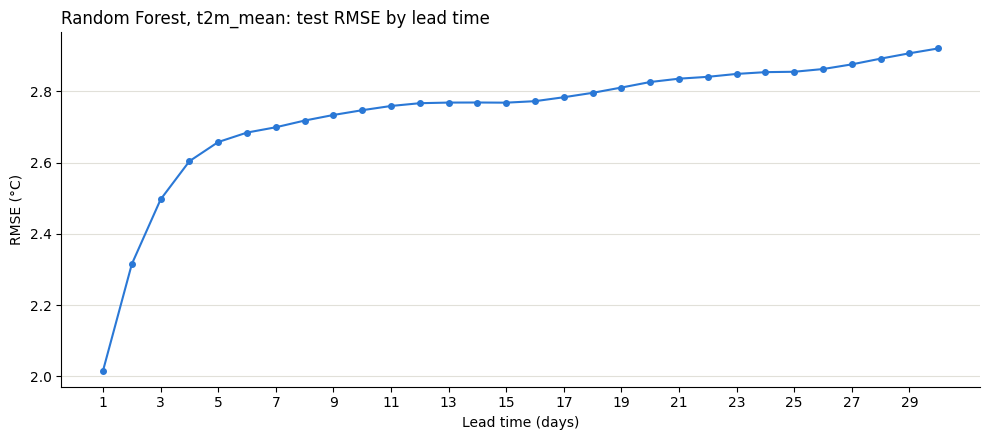

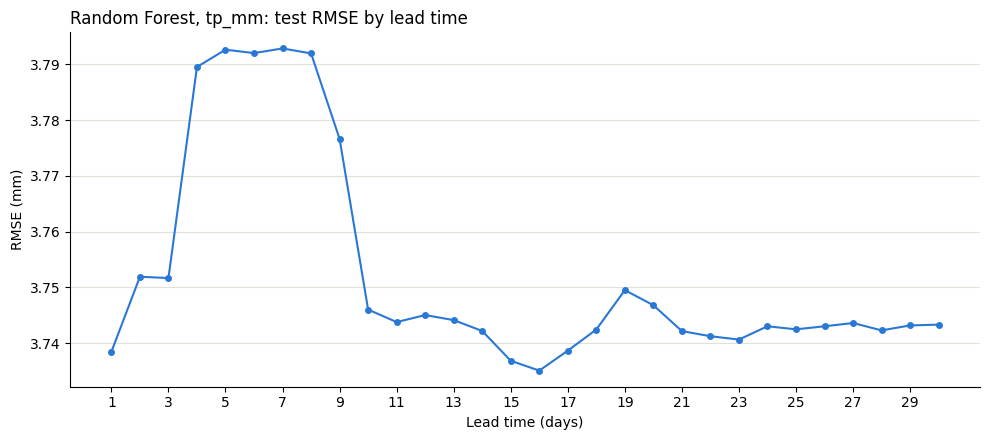

In [ ]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_test[target],
        y_test_pred[target],
        f"Random Forest, {target}: test RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val":   (y_val[target],   y_val_pred[target]),
            "Test":  (y_test[target],  y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

La Random Forest non riesce a catturare informazioni predittive sufficientemente utili per le precipitazioni.

Non è principalmente un problema di overfitting: anche il training R² è molto basso.

## EXTRA TREES

### DEFAULT PERFORMANCE

In [ ]:
et = ExtraTreesRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

et.fit(X_train, y_train)

print(f"Number of trees: {et.n_estimators}")
print("Training completed.")

Number of trees: 100
Training completed.


In [ ]:
y_train_pred = pd.DataFrame(
    et.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    et.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

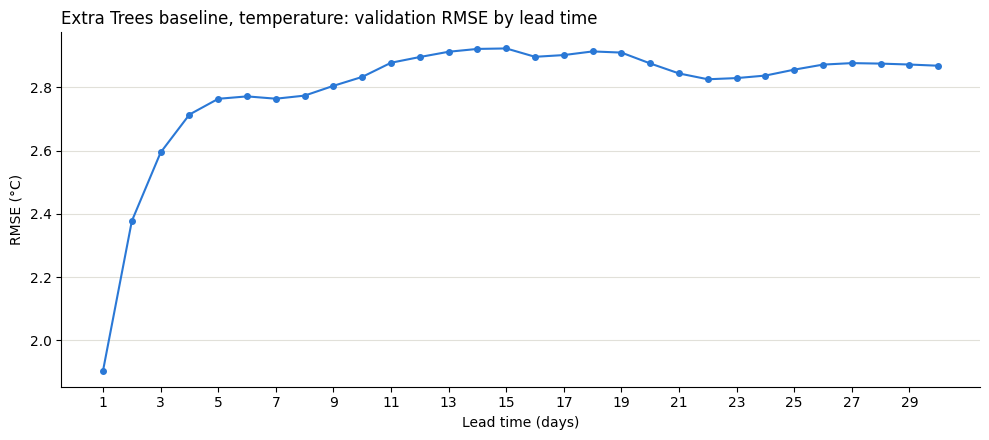

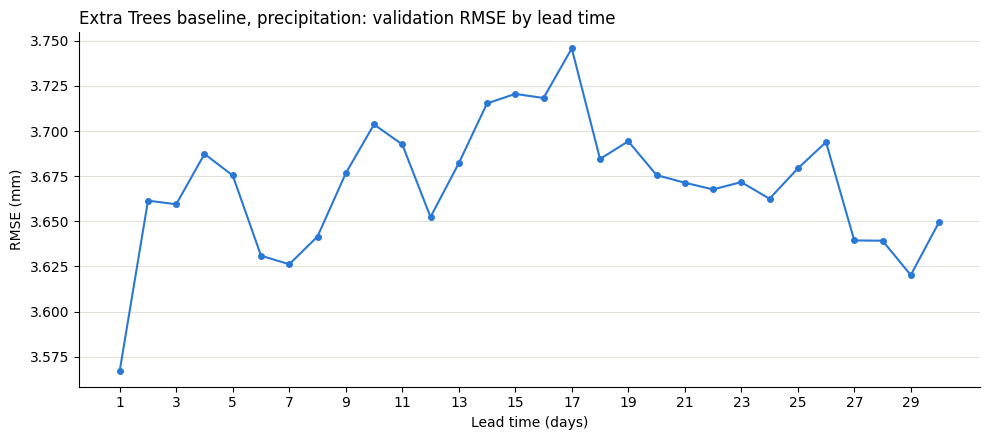

In [ ]:
metrics.plot_rmse(
    y_val["t2m_mean"],
    y_val_pred["t2m_mean"],
    "Extra Trees baseline, temperature: validation RMSE by lead time",
    "°C"
)

table = metrics.metrics_table(
    {
        "Train": (y_train["t2m_mean"], y_train_pred["t2m_mean"]),
        "Val": (y_val["t2m_mean"], y_val_pred["t2m_mean"])
    },
    tolerance=2
)

display(table.style.format("{:.3f}"))


metrics.plot_rmse(
    y_val["tp_mm"],
    y_val_pred["tp_mm"],
    "Extra Trees baseline, precipitation: validation RMSE by lead time",
    "mm"
)

table = metrics.metrics_table(
    {
        "Train": (y_train["tp_mm"], y_train_pred["tp_mm"]),
        "Val": (y_val["tp_mm"], y_val_pred["tp_mm"])
    }
)

display(table.style.format("{:.3f}"))

### MANUAL HYPERPARAMETER SEARCH


In [ ]:
def evaluate_et_config(max_depth, min_samples_leaf, max_features):

    model = ExtraTreesRegressor(
        n_estimators=100,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = pd.DataFrame(
        model.predict(X_val),
        index=y_val.index,
        columns=y_val.columns
    )

    normalized_mae = (
        (y_val - y_pred).abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": max_features,
        "Val normalized MAE": normalized_mae,
        "Val temp MAE": metrics.get_mean_absolute_error(
            y_val["t2m_mean"], y_pred["t2m_mean"]
        ),
        "Val precip MAE": metrics.get_mean_absolute_error(
            y_val["tp_mm"], y_pred["tp_mm"]
        )
    }

In [ ]:
depths = [10, 20, None]
min_leaves = [1, 10, 30]
max_features_options = [0.5, 0.7, 1.0]

results = []

for depth, min_leaf, max_features in product(
    depths, min_leaves, max_features_options
):
    results.append(
        evaluate_et_config(depth, min_leaf, max_features)
    )

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("Val normalized MAE")
    .reset_index(drop=True)
    .round(4)
)

,max_depth,min_samples_leaf,max_features,Val normalized MAE,Val temp MAE,Val precip MAE
0,10.0,30,0.7,0.4136,2.1065,2.0076
1,20.0,30,0.7,0.4137,2.1061,2.0089
2,NaN,30,0.7,0.4137,2.1061,2.0089
3,NaN,30,1.0,0.4137,2.1047,2.0097
4,20.0,30,1.0,0.4137,2.1047,2.0097
5,10.0,30,0.5,0.4140,2.1127,2.0075
6,10.0,10,0.5,0.4140,2.1013,2.0130
7,10.0,30,1.0,0.4140,2.1039,2.0119
8,20.0,30,0.5,0.4140,2.1108,2.0088
9,NaN,30,0.5,0.4140,2.1108,2.0088


### OPTUNA

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators", 100, 400, step=100
    )

    max_depth = trial.suggest_categorical(
        "max_depth", [8, 10, 12, 15, 20, None]
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 10, 80, log=True
    )

    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2 * min_samples_leaf,
        500,
        log=True
    )

    max_features = trial.suggest_categorical(
        "max_features", [0.5, 0.7, 1.0]
    )

    model = ExtraTreesRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    normalized_mae = (
        np.abs(y_val.to_numpy() - y_pred)
        / target_scales.to_numpy()
    ).mean()

    return normalized_mae


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study_et = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study_et.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

print("Best validation normalized MAE:", study_et.best_value)
print("Best hyperparameters:", study_et.best_params)

[I 2026-11-25 11:53:41,159] A new study created in memory with name: no-name-cc9da772-9c71-4b17-b158-0f5b81f8dd1c


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-25 11:53:47,816] Trial 0 finished with value: 0.41336984389352693 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 60, 'min_samples_split': 283, 'max_features': 1.0}. Best is trial 0 with value: 0.41336984389352693.
[I 2026-11-25 11:54:05,380] Trial 1 finished with value: 0.41199933923122267 and parameters: {'n_estimators': 400, 'max_depth': 20, 'min_samples_leaf': 18, 'min_samples_split': 179, 'max_features': 1.0}. Best is trial 1 with value: 0.41199933923122267.
[I 2026-11-25 11:54:11,727] Trial 2 finished with value: 0.41328149935047354 and parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 14, 'min_samples_split': 33, 'max_features': 0.7}. Best is trial 1 with value: 0.41199933923122267.
[I 2026-11-25 11:54:17,647] Trial 3 finished with value: 0.41439825109783357 and parameters: {'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 66, 'min_samples_split': 186, 'max_features': 0.5}. Best is trial 1 with value: 0.4119993392

In [ ]:
trials_df = study_et.trials_dataframe()

display(
    trials_df.sort_values("value")
    [["number", "value"]]
    .head(10)
)

,number,value
86,86,0.411683
93,93,0.411780
96,96,0.411783
49,49,0.411824
98,98,0.411824
40,40,0.411827
39,39,0.411867
25,25,0.411937
83,83,0.411958
97,97,0.411959


### TESTING

In [ ]:
best_params = study_et.best_params

print("Best hyperparameters:")
print(best_params)

et = ExtraTreesRegressor(
    **best_params,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

et.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    et.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    et.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

y_test_pred = pd.DataFrame(
    et.predict(X_test),
    index=y_test.index,
    columns=y_test.columns
)

Best hyperparameters:
{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 17, 'min_samples_split': 142, 'max_features': 1.0}


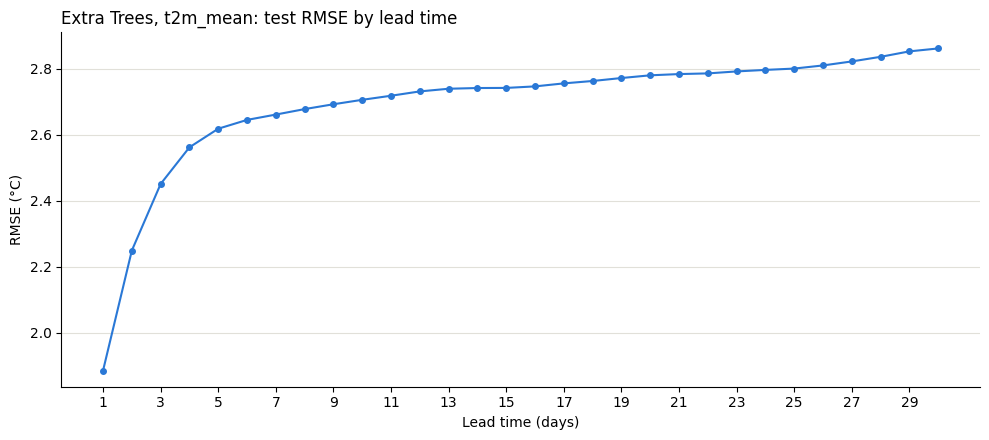

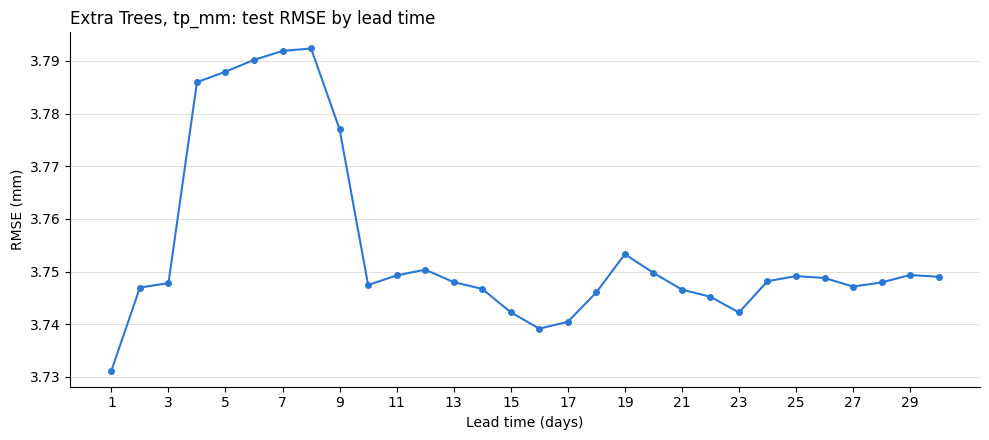

In [ ]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_test[target],
        y_test_pred[target],
        f"Extra Trees, {target}: test RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val":   (y_val[target],   y_val_pred[target]),
            "Test":  (y_test[target],  y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

## GRADIENT BOOSTING

### DEFAULT PERFORMANCE

In [5]:
gb = MultiOutputRegressor(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    n_jobs=-1
)

gb.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    gb.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    gb.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

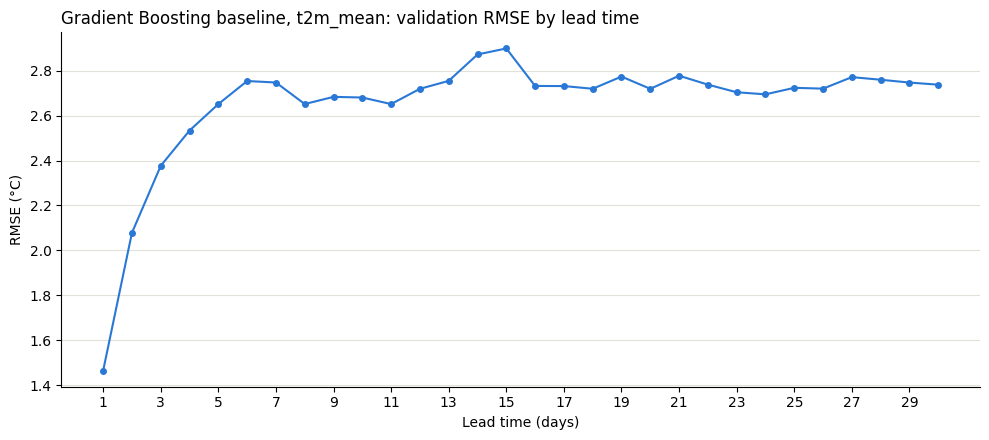

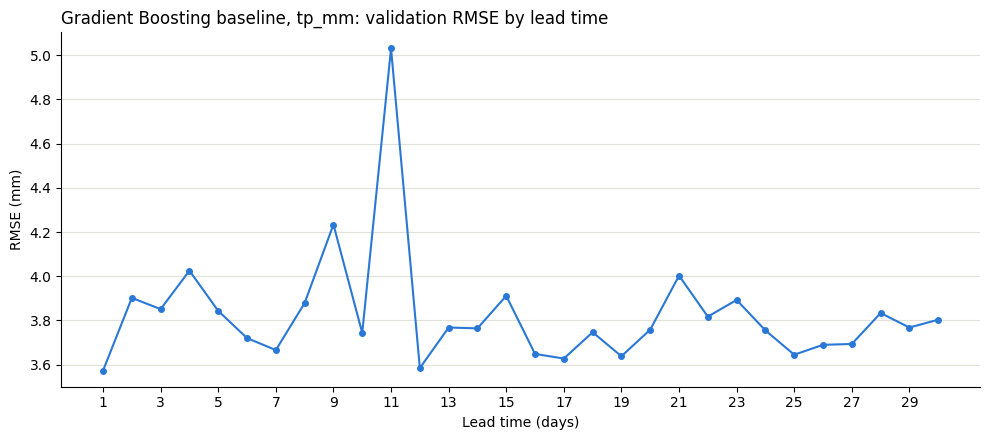

In [6]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_val[target],
        y_val_pred[target],
        f"Gradient Boosting baseline, {target}: validation RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val": (y_val[target], y_val_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

NOTE: Possibile overfitting su precipitazioni

### MANUAL HYPERPARAMETER SEARCH

In [ ]:
def evaluate_gb_config(n_estimators, learning_rate, max_depth,
                       min_samples_leaf, subsample):

    model = MultiOutputRegressor(
        GradientBoostingRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            subsample=subsample,
            random_state=RANDOM_STATE
        ),
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = pd.DataFrame(
        model.predict(X_val),
        index=y_val.index,
        columns=y_val.columns
    )

    normalized_mae = (
        (y_val - y_pred).abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    return {
        "n_estimators": n_estimators,
        "learning_rate": learning_rate,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "subsample": subsample,
        "Val normalized MAE": normalized_mae
    }

In [ ]:
results_gb = []

configs = product(
    [100, 200],       # n_estimators
    [0.05, 0.1],      # learning_rate
    [2, 3],           # max_depth
    [10, 20],         # min_samples_leaf
    [0.8]             # subsample
)

for config in configs:
    result = evaluate_gb_config(*config)
    results_gb.append(result)

    print(
        f"Config: {config} | "
        f"Val normalized MAE: {result['Val normalized MAE']:.5f}"
    )

results_gb = pd.DataFrame(results_gb)
results_gb = results_gb.sort_values("Val normalized MAE")

display(results_gb.style.format({
    "learning_rate": "{:.3f}",
    "Val normalized MAE": "{:.5f}"
}))

Config: (100, 0.05, 2, 10, 0.8) | Val normalized MAE: 0.41977
Config: (100, 0.05, 2, 20, 0.8) | Val normalized MAE: 0.41498
Config: (100, 0.05, 3, 10, 0.8) | Val normalized MAE: 0.42658
Config: (100, 0.05, 3, 20, 0.8) | Val normalized MAE: 0.41457
Config: (100, 0.1, 2, 10, 0.8) | Val normalized MAE: 0.42647
Config: (100, 0.1, 2, 20, 0.8) | Val normalized MAE: 0.41381
Config: (100, 0.1, 3, 10, 0.8) | Val normalized MAE: 0.43545
Config: (100, 0.1, 3, 20, 0.8) | Val normalized MAE: 0.41600
Config: (200, 0.05, 2, 10, 0.8) | Val normalized MAE: 0.41951
Config: (200, 0.05, 2, 20, 0.8) | Val normalized MAE: 0.40953
Config: (200, 0.05, 3, 10, 0.8) | Val normalized MAE: 0.42958
Config: (200, 0.05, 3, 20, 0.8) | Val normalized MAE: 0.41346
Config: (200, 0.1, 2, 10, 0.8) | Val normalized MAE: 0.42753
Config: (200, 0.1, 2, 20, 0.8) | Val normalized MAE: 0.41435
Config: (200, 0.1, 3, 10, 0.8) | Val normalized MAE: 0.44521
Config: (200, 0.1, 3, 20, 0.8) | Val normalized MAE: 0.41844


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Val normalized MAE
9,200,0.050,2,20,0.800000,0.40953
11,200,0.050,3,20,0.800000,0.41346
5,100,0.100,2,20,0.800000,0.41381
13,200,0.100,2,20,0.800000,0.41435
3,100,0.050,3,20,0.800000,0.41457
1,100,0.050,2,20,0.800000,0.41498
7,100,0.100,3,20,0.800000,0.41600
15,200,0.100,3,20,0.800000,0.41844
8,200,0.050,2,10,0.800000,0.41951
0,100,0.050,2,10,0.800000,0.41977


### OPTUNA

In [ ]:
def objective(trial):

    n_estimators = trial.suggest_int(
        "n_estimators", 100, 400, step=100
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 0.01, 0.15, log=True
    )

    max_depth = trial.suggest_int(
        "max_depth", 2, 4
    )

    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf", 10, 40, log=True
    )

    subsample = trial.suggest_float(
        "subsample", 0.6, 1.0
    )

    model = MultiOutputRegressor(
        GradientBoostingRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            subsample=subsample,
            random_state=RANDOM_STATE
        ),
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    normalized_mae = (
        np.abs(y_val.to_numpy() - y_pred)
        / target_scales.to_numpy()
    ).mean()

    return normalized_mae

In [ ]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study_gb = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study_gb.optimize(
    objective,
    n_trials=10,
    show_progress_bar=True
)

print("Best validation normalized MAE:", study_gb.best_value)
print("Best hyperparameters:", study_gb.best_params)

trials_df = study_gb.trials_dataframe()

display(
    trials_df.sort_values("value")
    [["number", "value"]]
    .head(10)
)

[I 2026-11-25 15:22:29,284] A new study created in memory with name: no-name-9003a742-b270-4058-b2f8-2d667d2436ca


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-25 15:42:01,240] Trial 0 finished with value: 0.4425534974421606 and parameters: {'n_estimators': 200, 'learning_rate': 0.13125830316209655, 'max_depth': 4, 'min_samples_leaf': 23, 'subsample': 0.6624074561769746}. Best is trial 0 with value: 0.4425534974421606.
[I 2026-11-25 15:54:50,424] Trial 1 finished with value: 0.46317853958456806 and parameters: {'n_estimators': 100, 'learning_rate': 0.011703388679635262, 'max_depth': 4, 'min_samples_leaf': 23, 'subsample': 0.8832290311184181}. Best is trial 0 with value: 0.4425534974421606.
[I 2026-11-25 16:04:48,946] Trial 2 finished with value: 0.4484901539796761 and parameters: {'n_estimators': 100, 'learning_rate': 0.13826189316223852, 'max_depth': 4, 'min_samples_leaf': 13, 'subsample': 0.6727299868828402}. Best is trial 0 with value: 0.4425534974421606.
[I 2026-11-25 16:12:46,453] Trial 3 finished with value: 0.42353306048296424 and parameters: {'n_estimators': 100, 'learning_rate': 0.02279379523765072, 'max_depth': 3, 'min_sa

,number,value
7,7,0.409915
9,9,0.413380
5,5,0.413704
6,6,0.414110
4,4,0.415319
8,8,0.415921
3,3,0.423533
0,0,0.442553
2,2,0.448490
1,1,0.463179


### TESTING

In [16]:
#best_params = study_gb.best_params
best_params = study_results["Gradient Boosting"]["best_params"]

print("Best hyperparameters:")
print(best_params)

gb = MultiOutputRegressor(
    GradientBoostingRegressor(
        **best_params,
        random_state=RANDOM_STATE
    ),
    n_jobs=-1
)

gb.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    gb.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    gb.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

y_test_pred = pd.DataFrame(
    gb.predict(X_test),
    index=y_test.index,
    columns=y_test.columns
)

Best hyperparameters:
{'n_estimators': 400, 'learning_rate': 0.022816739880816207, 'max_depth': 2, 'min_samples_leaf': 26, 'subsample': 0.7760609974958406}


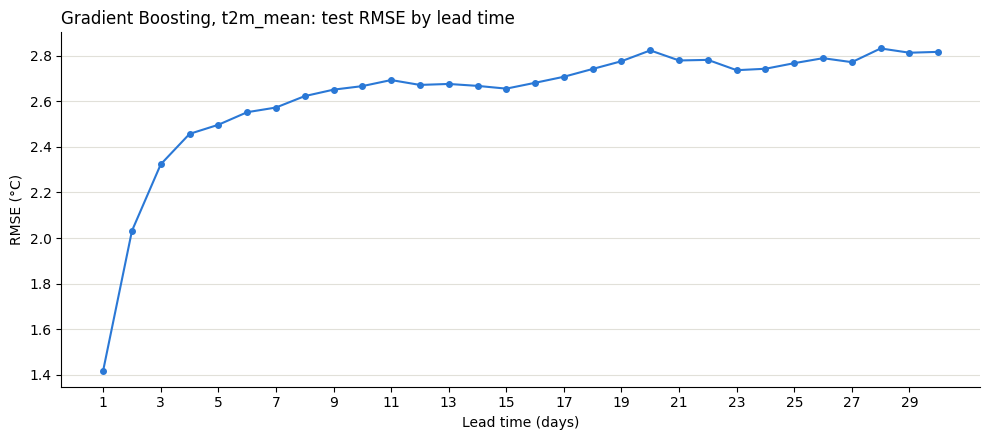

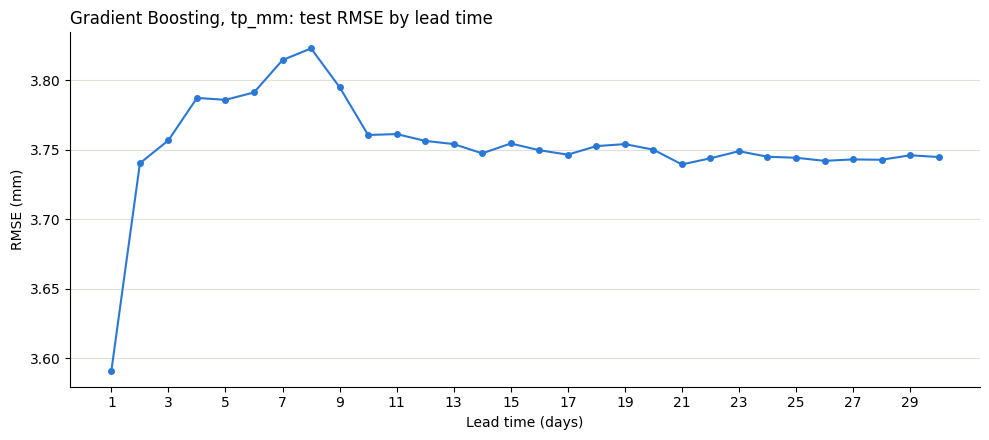

In [ ]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_test[target],
        y_test_pred[target],
        f"Gradient Boosting, {target}: test RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val": (y_val[target], y_val_pred[target]),
            "Test": (y_test[target], y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

## XGBOOST

In [ ]:
from xgboost import XGBRegressor

### DEFAULT PERFORMANCE

In [ ]:
xgb = MultiOutputRegressor(
    XGBRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    xgb.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    xgb.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

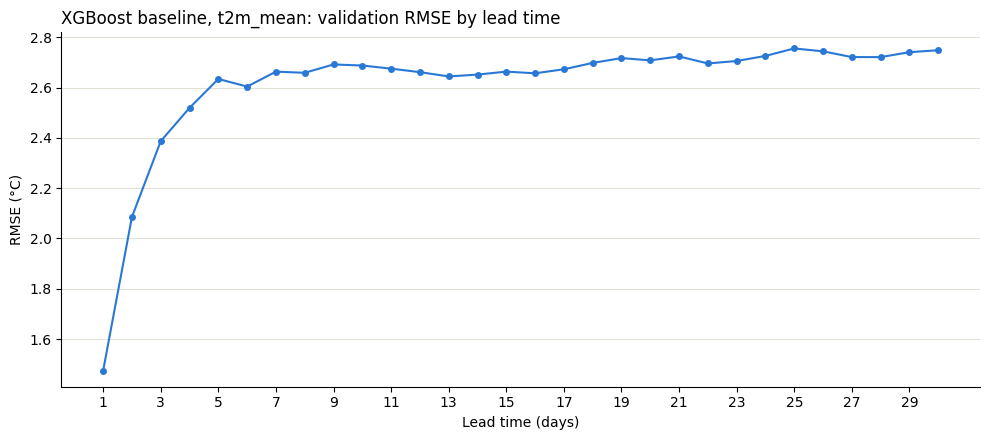

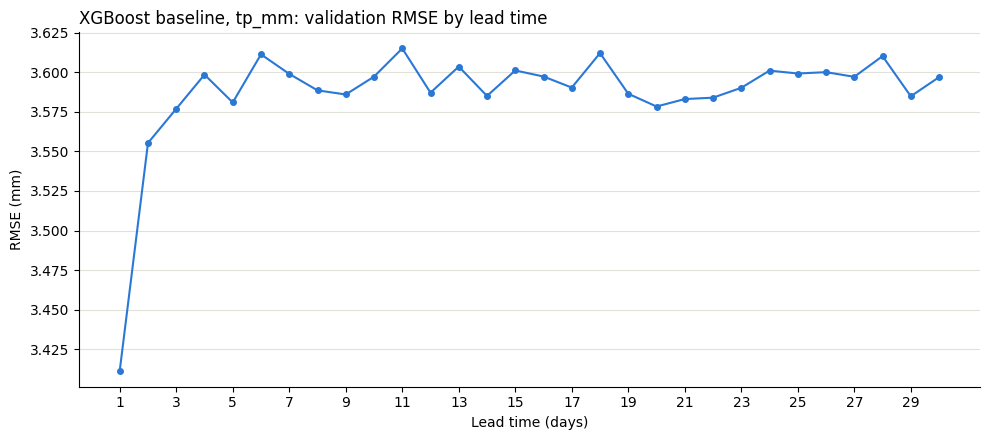

In [ ]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_val[target],
        y_val_pred[target],
        f"XGBoost baseline, {target}: validation RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val": (y_val[target], y_val_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

### MANUAL HYPERPARAMETER SEARCH

In [ ]:
def evaluate_xgb_config(n_estimators, learning_rate, max_depth,
                        min_child_weight, subsample, colsample_bytree):

    model = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_child_weight=min_child_weight,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0
        ),
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = pd.DataFrame(
        model.predict(X_val),
        index=y_val.index,
        columns=y_val.columns
    )

    normalized_mae = (
        (y_val - y_pred)
        .abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    return {
        "n_estimators": n_estimators,
        "learning_rate": learning_rate,
        "max_depth": max_depth,
        "min_child_weight": min_child_weight,
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "Val normalized MAE": normalized_mae,
        "Val temp MAE": metrics.get_mean_absolute_error(
            y_val["t2m_mean"], y_pred["t2m_mean"]
        ),
        "Val precip MAE": metrics.get_mean_absolute_error(
            y_val["tp_mm"], y_pred["tp_mm"]
        )
    }

In [ ]:
results_xgb = []

configs = [
    (100, 0.05, 3, 1, 0.8, 0.8),
    (200, 0.05, 3, 1, 0.8, 0.8),
    (300, 0.05, 3, 1, 0.8, 0.8),
    (200, 0.10, 3, 1, 0.8, 0.8),
    (200, 0.05, 5, 1, 0.8, 0.8),
    (200, 0.05, 5, 5, 0.8, 0.8),
    (200, 0.10, 5, 5, 0.8, 0.8),
    (300, 0.05, 5, 5, 0.8, 0.8)
]

for config in configs:

    result = evaluate_xgb_config(*config)
    results_xgb.append(result)

    print(
        f"Config: {config} | "
        f"Val normalized MAE: {result['Val normalized MAE']:.5f}"
    )

results_xgb = (
    pd.DataFrame(results_xgb)
    .sort_values("Val normalized MAE")
    .reset_index(drop=True)
)

display(
    results_xgb.style.format({
        "learning_rate": "{:.3f}",
        "subsample": "{:.2f}",
        "colsample_bytree": "{:.2f}",
        "Val normalized MAE": "{:.5f}",
        "Val temp MAE": "{:.3f}",
        "Val precip MAE": "{:.3f}"
    })
)

Config: (100, 0.05, 3, 1, 0.8, 0.8) | Val normalized MAE: 0.41772
Config: (200, 0.05, 3, 1, 0.8, 0.8) | Val normalized MAE: 0.41834
Config: (300, 0.05, 3, 1, 0.8, 0.8) | Val normalized MAE: 0.42401
Config: (200, 0.1, 3, 1, 0.8, 0.8) | Val normalized MAE: 0.43007
Config: (200, 0.05, 5, 1, 0.8, 0.8) | Val normalized MAE: 0.43976
Config: (200, 0.05, 5, 5, 0.8, 0.8) | Val normalized MAE: 0.42870
Config: (200, 0.1, 5, 5, 0.8, 0.8) | Val normalized MAE: 0.45253
Config: (300, 0.05, 5, 5, 0.8, 0.8) | Val normalized MAE: 0.43856


,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,Val normalized MAE,Val temp MAE,Val precip MAE
0,100,0.050,3,1,0.80,0.80,0.41772,2.070,2.055
1,200,0.050,3,1,0.80,0.80,0.41834,2.070,2.060
2,300,0.050,3,1,0.80,0.80,0.42401,2.081,2.095
3,200,0.050,5,5,0.80,0.80,0.42870,2.100,2.121
4,200,0.100,3,1,0.80,0.80,0.43007,2.099,2.131
5,300,0.050,5,5,0.80,0.80,0.43856,2.122,2.182
6,200,0.050,5,1,0.80,0.80,0.43976,2.104,2.199
7,200,0.100,5,5,0.80,0.80,0.45253,2.170,2.261


### OPTUNA

In [ ]:
def objective(trial):

    # Hyperparameters
    n_estimators = trial.suggest_int(
        "n_estimators", 50, 300, step=50
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 0.01, 0.1, log=True
    )

    max_depth = trial.suggest_int(
        "max_depth", 2, 6
    )

    min_child_weight = trial.suggest_int(
        "min_child_weight", 1, 15
    )

    subsample = trial.suggest_float(
        "subsample", 0.6, 1.0
    )

    colsample_bytree = trial.suggest_float(
        "colsample_bytree", 0.6, 1.0
    )

    gamma = trial.suggest_float(
        "gamma", 0, 5
    )

    reg_lambda = trial.suggest_float(
        "reg_lambda", 0.1, 20, log=True
    )

    # Model
    model = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_child_weight=min_child_weight,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            gamma=gamma,
            reg_lambda=reg_lambda,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0
        ),
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    normalized_mae = (
        np.abs(y_val.to_numpy() - y_pred)
        / target_scales.to_numpy()
    ).mean()

    return normalized_mae

In [ ]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study_xgb = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study_xgb.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

print("Best validation normalized MAE:", study_xgb.best_value)
print("Best hyperparameters:", study_xgb.best_params)

trials_df = study_xgb.trials_dataframe()

display(
    trials_df.sort_values("value")
    [["number", "value"]]
    .head(10)
)

[I 2026-11-25 18:42:00,350] A new study created in memory with name: no-name-8d466f7f-2350-4193-8534-8290563a68b8


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-25 18:42:34,649] Trial 0 finished with value: 0.42391242225487064 and parameters: {'n_estimators': 150, 'learning_rate': 0.08927180304353628, 'max_depth': 5, 'min_child_weight': 9, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_lambda': 9.842315738502599}. Best is trial 0 with value: 0.42391242225487064.
[I 2026-11-25 18:42:51,614] Trial 1 finished with value: 0.40983238770349484 and parameters: {'n_estimators': 200, 'learning_rate': 0.051059032093947576, 'max_depth': 2, 'min_child_weight': 15, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'gamma': 0.9091248360355031, 'reg_lambda': 0.26425260575499165}. Best is trial 1 with value: 0.40983238770349484.
[I 2026-11-25 18:43:11,504] Trial 2 finished with value: 0.4178634166439109 and parameters: {'n_estimators': 100, 'learning_rate': 0.03347776308515933, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.8447411578889518, 'colsample_bytree':

,number,value
92,92,0.407266
32,32,0.407291
91,91,0.407372
42,42,0.407409
68,68,0.407430
95,95,0.407454
81,81,0.407478
48,48,0.407489
64,64,0.407489
63,63,0.407505


### TESTING

In [ ]:
best_params = study_xgb.best_params

print("Best hyperparameters:")
print(best_params)

xgb = MultiOutputRegressor(
    XGBRegressor(
        **best_params,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0
    ),
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_train_pred = pd.DataFrame(
    xgb.predict(X_train),
    index=y_train.index,
    columns=y_train.columns
)

y_val_pred = pd.DataFrame(
    xgb.predict(X_val),
    index=y_val.index,
    columns=y_val.columns
)

y_test_pred = pd.DataFrame(
    xgb.predict(X_test),
    index=y_test.index,
    columns=y_test.columns
)

Best hyperparameters:
{'n_estimators': 300, 'learning_rate': 0.06246081645465873, 'max_depth': 2, 'min_child_weight': 14, 'subsample': 0.9751912479114022, 'colsample_bytree': 0.7134057312988303, 'gamma': 1.7419094936803832, 'reg_lambda': 0.1277609140115261}


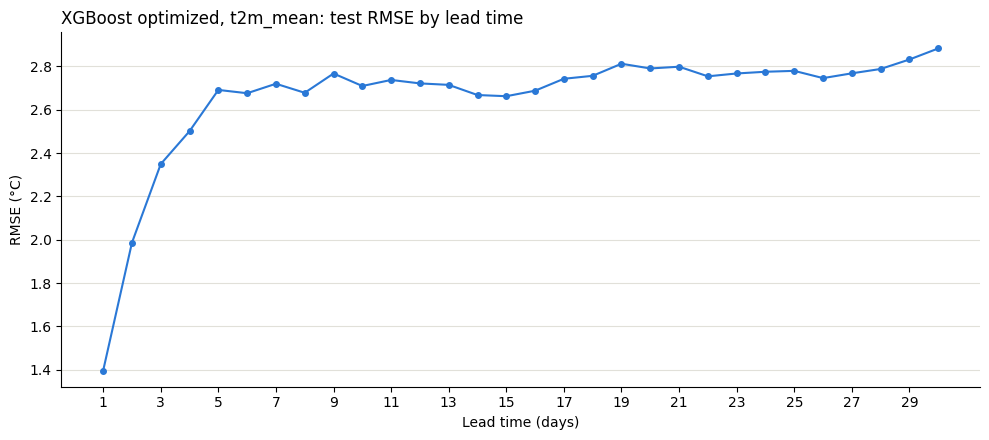

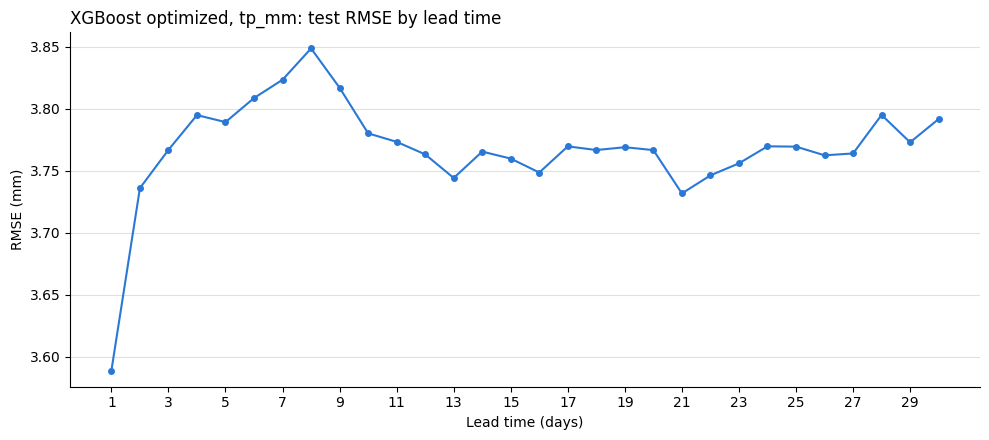

In [ ]:
for target, unit, tol in [
    ("t2m_mean", "°C", 2),
    ("tp_mm", "mm", None)
]:
    metrics.plot_rmse(
        y_test[target],
        y_test_pred[target],
        f"XGBoost optimized, {target}: test RMSE by lead time",
        unit
    )

    table = metrics.metrics_table(
        {
            "Train": (y_train[target], y_train_pred[target]),
            "Val": (y_val[target], y_val_pred[target]),
            "Test": (y_test[target], y_test_pred[target])
        },
        tolerance=tol
    )

    display(table.style.format("{:.3f}"))

## COMPARISON

In [17]:
models = {
    "Random Forest": rf,
    "Extra Trees": et,
    "Gradient Boosting": gb,
    "XGBoost": xgb
}

test_predictions = {}

for name, model in models.items():
    test_predictions[name] = pd.DataFrame(
        model.predict(X_test),
        index=y_test.index,
        columns=y_test.columns
    )

In [18]:
normalized_mae_results = []

for name in models:

    y_pred = test_predictions[name]

    temperature_mae = (
        (y_test["t2m_mean"] - y_pred["t2m_mean"])
        .abs()
        .div(target_scales["t2m_mean"])
        .to_numpy()
        .mean()
    )

    precipitation_mae = (
        (y_test["tp_mm"] - y_pred["tp_mm"])
        .abs()
        .div(target_scales["tp_mm"])
        .to_numpy()
        .mean()
    )

    overall_mae = (
        (y_test - y_pred)
        .abs()
        .div(target_scales, axis=1)
        .to_numpy()
        .mean()
    )

    normalized_mae_results.append({
        "Model": name,
        "Temperature": temperature_mae,
        "Precipitation": precipitation_mae,
        "Overall": overall_mae
    })

normalized_mae_results = pd.DataFrame(normalized_mae_results)

In [19]:
temperature_ranking = (
    normalized_mae_results[["Model", "Temperature"]]
    .sort_values("Temperature")
    .reset_index(drop=True)
)

temperature_ranking.index += 1
temperature_ranking.index.name = "Rank"

display(temperature_ranking.style.format({
    "Temperature": "{:.5f}"
}))

,Model,Temperature
Rank,,
1,Gradient Boosting,0.27162
2,XGBoost,0.27445
3,Extra Trees,0.27805
4,Random Forest,0.28307


In [20]:
precipitation_ranking = (
    normalized_mae_results[["Model", "Precipitation"]]
    .sort_values("Precipitation")
    .reset_index(drop=True)
)

precipitation_ranking.index += 1
precipitation_ranking.index.name = "Rank"

display(precipitation_ranking.style.format({
    "Precipitation": "{:.5f}"
}))

,Model,Precipitation
Rank,,
1,XGBoost,0.54735
2,Random Forest,0.54891
3,Extra Trees,0.55145
4,Gradient Boosting,0.55577


In [21]:
overall_ranking = (
    normalized_mae_results[["Model", "Overall"]]
    .sort_values("Overall")
    .reset_index(drop=True)
)

overall_ranking.index += 1
overall_ranking.index.name = "Rank"

display(overall_ranking.style.format({
    "Overall": "{:.5f}"
}))

,Model,Overall
Rank,,
1,XGBoost,0.41090
2,Gradient Boosting,0.41370
3,Extra Trees,0.41475
4,Random Forest,0.41599


In [22]:
final_comparison = (
    normalized_mae_results
    .sort_values("Overall")
    .reset_index(drop=True)
)

final_comparison.index += 1
final_comparison.index.name = "Rank"

display(final_comparison.style.format({
    "Temperature": "{:.5f}",
    "Precipitation": "{:.5f}",
    "Overall": "{:.5f}"
}))

,Model,Temperature,Precipitation,Overall
Rank,,,,
1,XGBoost,0.27445,0.54735,0.41090
2,Gradient Boosting,0.27162,0.55577,0.41370
3,Extra Trees,0.27805,0.55145,0.41475
4,Random Forest,0.28307,0.54891,0.41599


In [23]:
best_temperature = temperature_ranking.iloc[0]
best_precipitation = precipitation_ranking.iloc[0]
best_overall = overall_ranking.iloc[0]

print("Best model for temperature:")
print(f"{best_temperature['Model']} — {best_temperature['Temperature']:.5f}")

print("\nBest model for precipitation:")
print(f"{best_precipitation['Model']} — {best_precipitation['Precipitation']:.5f}")

print("\nBest overall model:")
print(f"{best_overall['Model']} — {best_overall['Overall']:.5f}")

Best model for temperature:
Gradient Boosting — 0.27162

Best model for precipitation:
XGBoost — 0.54735

Best overall model:
XGBoost — 0.41090


## SAVE MODELS

In [ ]:
# RUNNARE QUESTA CELLA, TOGLIENDO IL COMMENTO MULTI-LINEA, SOLO SE SI VUOLE SALVARE I RISULTATI SE SI PARTE DA UN JOBLIB CARICATO

'''import joblib
import sklearn
import xgboost as xgb_pkg
import optuna
from google.colab import files

artifacts = joblib.load("/content/ensemble_results.joblib")

rf = artifacts["models"]["Random Forest"]
et = artifacts["models"]["Extra Trees"]
gb = artifacts["models"]["Gradient Boosting"]
xgb = artifacts["models"]["XGBoost"]

X_train = artifacts["data"]["X_train"]
X_val = artifacts["data"]["X_val"]
X_test = artifacts["data"]["X_test"]

y_train = artifacts["data"]["y_train"]
y_val = artifacts["data"]["y_val"]
y_test = artifacts["data"]["y_test"]

study_results = artifacts["study_results"]
test_predictions = artifacts["test_predictions"]
target_scales = artifacts["target_scales"]

comparison_tables = artifacts.get("comparison_tables")
summary_scores = artifacts.get("summary_scores")

artifacts = {
    "models": {
        "Random Forest": rf,
        "Extra Trees": et,
        "Gradient Boosting": gb,
        "XGBoost": xgb
    },

    "data": {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    },

    "study_results": study_results,

    "test_predictions": test_predictions,

    "target_scales": target_scales,

    "versions": {
        "sklearn": sklearn.__version__,
        "xgboost": xgb_pkg.__version__,
        "optuna": optuna.__version__
    }
}

for key in [
    "comparison_tables",
    "summary_scores",
    "normalized_mae_results",
    "temperature_ranking",
    "precipitation_ranking",
    "overall_ranking",
    "final_comparison"
]:
    if key in globals() and globals()[key] is not None:
        artifacts[key] = globals()[key]

artifact_path = "/content/ensemble_results.joblib"

joblib.dump(
    artifacts,
    artifact_path,
    compress=3
)

print("Artifacts saved successfully.")

files.download(artifact_path)'''

In [ ]:
# RUNNARE QUESTA CELLA, TOGLIENDO IL COMMENTO MULTI-LINEA, SOLO SE SI VUOLE SALVARE I RISULTATI UNA VOLTA ESEGUITO TUTTO IL NOTEBOOK

'''import joblib
import sklearn
import xgboost as xgb_pkg
from google.colab import files

study_results = {
    "Random Forest": {
        "best_params": study_rf.best_params,
        "best_value": study_rf.best_value,
        "trials": study_rf.trials_dataframe()
    },
    "Extra Trees": {
        "best_params": study_et.best_params,
        "best_value": study_et.best_value,
        "trials": study_et.trials_dataframe()
    },
    "Gradient Boosting": {
        "best_params": study_gb.best_params,
        "best_value": study_gb.best_value,
        "trials": study_gb.trials_dataframe()
    },
    "XGBoost": {
        "best_params": study_xgb.best_params,
        "best_value": study_xgb.best_value,
        "trials": study_xgb.trials_dataframe()
    }
}

artifacts = {

    "models": {
        "Random Forest": rf,
        "Extra Trees": et,
        "Gradient Boosting": gb,
        "XGBoost": xgb
    },

    "data": {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    },

    "study_results": study_results,

    "test_predictions": test_predictions,
    "comparison_tables": comparison_tables,
    "summary_scores": summary_scores,

    "target_scales": target_scales,

    "versions": {
        "sklearn": sklearn.__version__,
        "xgboost": xgb_pkg.__version__,
        "optuna": optuna.__version__
    }
}

artifact_path = "/content/ensemble_results.joblib"

joblib.dump(
    artifacts,
    artifact_path,
    compress=3
)

print("Artifacts saved successfully.")

files.download(artifact_path)'''